In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
!python -m pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 541909
Number of Columns: 8


In [9]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [11]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [12]:
print("Total Unique Customers:", df["CustomerID"].nunique())

Total Unique Customers: 4372


In [13]:
print("Total Unique Products:", df["StockCode"].nunique())

Total Unique Products: 4070


In [14]:
print("Total Unique Invoices:", df["InvoiceNo"].nunique())

Total Unique Invoices: 25900


In [15]:
country_counts = df["Country"].value_counts()

print("Top 10 Countries by Transactions:")
print(country_counts.head(10))

Top 10 Countries by Transactions:
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64


In [16]:
print("Top 10 Products:")

print(df["Description"].value_counts().head(10))

Top 10 Products:
Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350
NATURAL SLATE HEART CHALKBOARD        1280
Name: count, dtype: int64


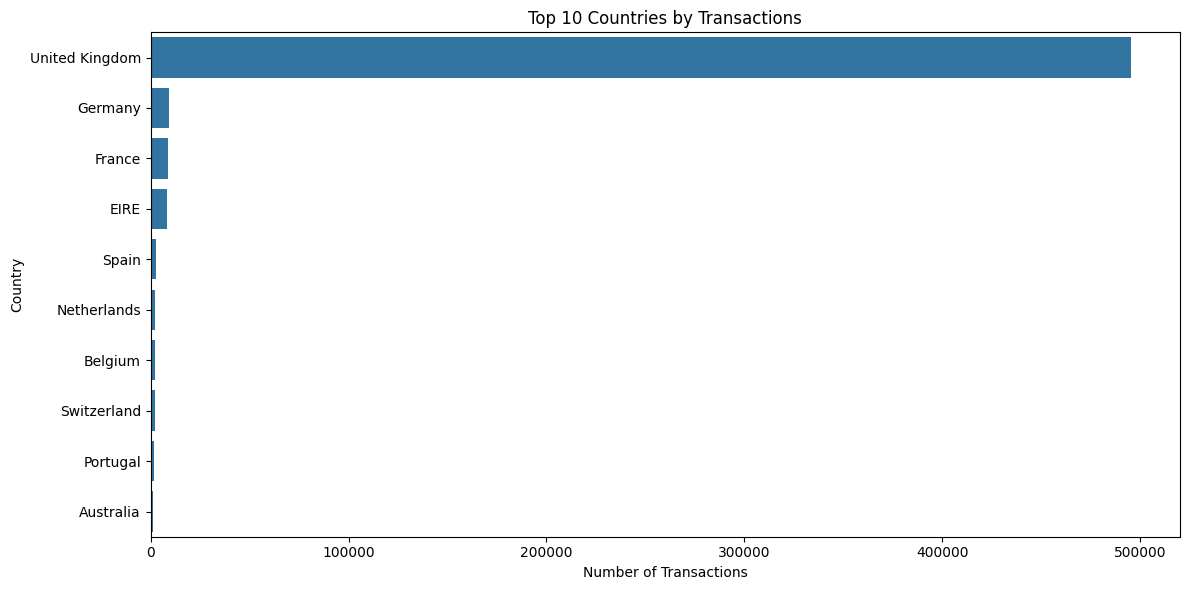

In [17]:
country_counts = df["Country"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title("Top 10 Countries by Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

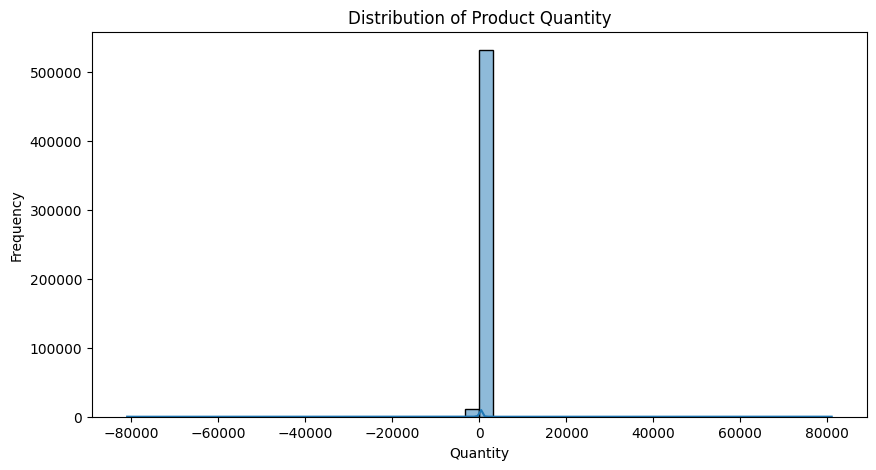

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Quantity"],
    bins=50,
    kde=True
)

plt.title("Distribution of Product Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.show()

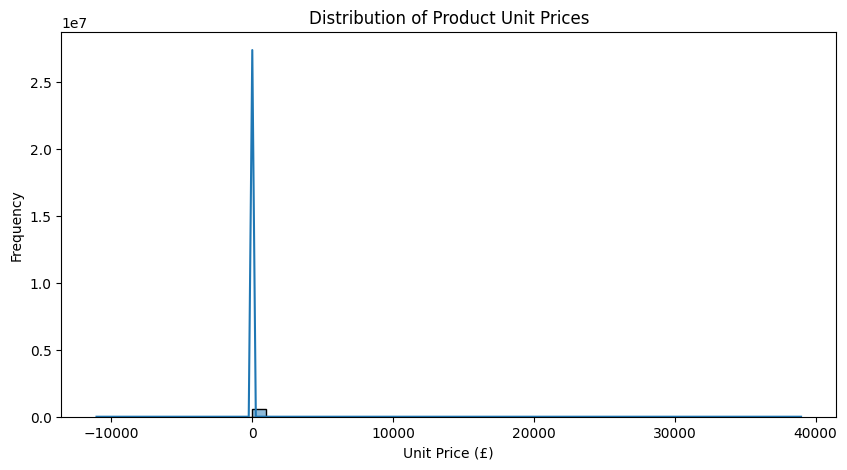

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["UnitPrice"],
    bins=50,
    kde=True
)

plt.title("Distribution of Product Unit Prices")
plt.xlabel("Unit Price (£)")
plt.ylabel("Frequency")

plt.show()

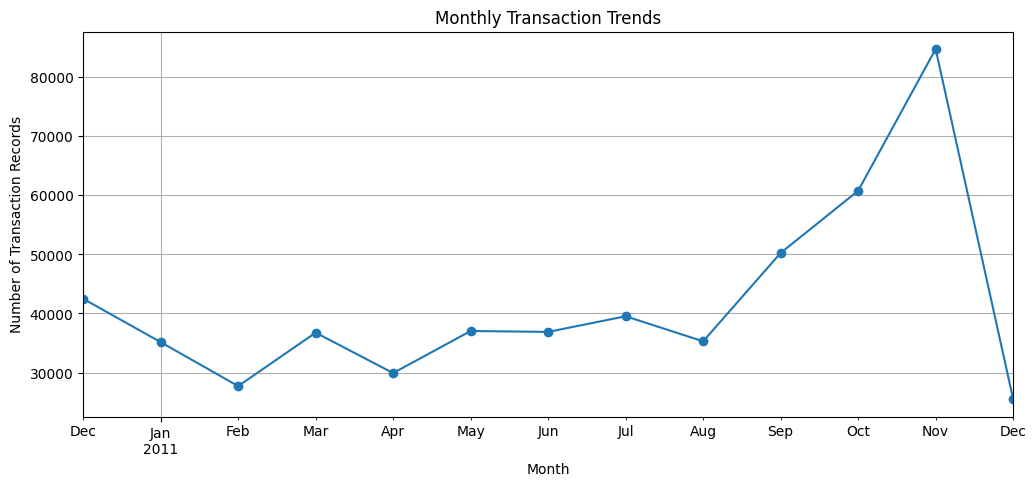

In [20]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

monthly_transactions = (
    df.set_index("InvoiceDate")
      .resample("ME")["InvoiceNo"]
      .count()
)

plt.figure(figsize=(12, 5))

monthly_transactions.plot(marker="o")

plt.title("Monthly Transaction Trends")
plt.xlabel("Month")
plt.ylabel("Number of Transaction Records")

plt.grid()
plt.show()

In [21]:
print("DAY 1 - DATASET ANALYSIS SUMMARY")
print("=" * 40)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Unique Customers:", df["CustomerID"].nunique())
print("Unique Products:", df["StockCode"].nunique())
print("Unique Invoices:", df["InvoiceNo"].nunique())
print("Countries:", df["Country"].nunique())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

DAY 1 - DATASET ANALYSIS SUMMARY
Total Records: 541909
Total Columns: 8
Unique Customers: 4372
Unique Products: 4070
Unique Invoices: 25900
Countries: 38

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268


In [22]:
df_clean = df.copy()

print("Working copy created successfully!")

Working copy created successfully!


In [23]:
print("Duplicates Before:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates After:", df_clean.duplicated().sum())

Duplicates Before: 5268
Duplicates After: 0


In [24]:
print("Missing Values Before:")
print(df_clean.isnull().sum())

df_clean = df_clean.dropna(
    subset=["CustomerID", "Description"]
)

print("\nMissing Values After:")
print(df_clean.isnull().sum())

Missing Values Before:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Missing Values After:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [25]:
df_clean = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Valid Transaction Records:", len(df_clean))

Valid Transaction Records: 392692


In [26]:
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [27]:
df_clean.to_csv(
    "online_retail_day1_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [28]:
print("DAY 1 FINAL SUMMARY")
print("=" * 40)

print("Original Records:", len(df))
print("Cleaned Records:", len(df_clean))
print("Unique Customers:", df_clean["CustomerID"].nunique())
print("Unique Products:", df_clean["StockCode"].nunique())
print("Unique Invoices:", df_clean["InvoiceNo"].nunique())
print("Countries:", df_clean["Country"].nunique())
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())

DAY 1 FINAL SUMMARY
Original Records: 541909
Cleaned Records: 392692
Unique Customers: 4338
Unique Products: 3665
Unique Invoices: 18532
Countries: 37
Missing Values: 0
Duplicates: 0
